В данном ноутбуке мы попробуем реализовать многоклассовую классификацию (3 класса) на PyTorch. 

Проверяем стоит ли у нас torch:

In [2]:
import torch
from torch import nn

torch.__version__

'2.2.0'

Определяем где будут храниться тензоры

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

<p>1. Создадим набор данных
    
Самое интересное, как создаем набор данных и организация хранения. Был взят популярный набор данных [про еду](https://www.kaggle.com/datasets/dansbecker/food-101). Что он из себя представляет: папки с названиями различных блюд (назовем это так). Как можно понять из названия, там 101 класс. Было взято 3: суши, гамбургеры и пицца. Есть много способов организовать разбивку. Пока что лучше взять и разбить руками, чтобы у вас был пример перед глазами и заодно стоит проверить качество изображений, далее в примерах будут уже примеры, где набор можно делить автоматически. Каждая папка, которую я выбрала имела 1 000 изображений класса. Было создано 2 папки с названиями test и train и закинула туда по три папки с классами. В каждой папке с классом соответственно по 800 (обучение) и 200 (тест) изображений.

Импортируем библиотечки:

In [4]:
import requests
from pathlib import Path

Не обязательная штука, но может пригодиться для автоматизации, а именно, создаем папку для наших данных:

In [5]:
data_path = Path("data/")
image_path = data_path / "su_ham_pizz"

Можно пойти и проверить, теперь у вас есть новая папка)

Закидываем туда наши 2 папки с test и train.

Можно запустить код ниже и проверить, существует папка или нет, тоже полезная штука:

In [6]:
if image_path.is_dir():
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)


data\su_ham_pizz directory exists.


У нас существует, соответственно и сообщение нам говорит об этом же)

<p>2. Подготовка данных

Посмотрим как хранятся данные и проверим, не оБшиблись ли мы. Полезная штука для просмотра содержимого:

In [7]:
import os
def walk_through_dir(dir_path):
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

In [8]:
walk_through_dir(image_path)

There are 2 directories and 1 images in 'data\su_ham_pizz'.
There are 3 directories and 0 images in 'data\su_ham_pizz\test'.
There are 0 directories and 200 images in 'data\su_ham_pizz\test\hamburger'.
There are 0 directories and 200 images in 'data\su_ham_pizz\test\pizza'.
There are 0 directories and 200 images in 'data\su_ham_pizz\test\sushi'.
There are 3 directories and 0 images in 'data\su_ham_pizz\train'.
There are 0 directories and 800 images in 'data\su_ham_pizz\train\hamburger'.
There are 0 directories and 800 images in 'data\su_ham_pizz\train\pizza'.
There are 0 directories and 800 images in 'data\su_ham_pizz\train\sushi'.


Получили то, что хотели. Первая строчка на говорит, что в папке у нас 2 папки: test и train. И далее идет вывод уже того, что в папках и количество.

Настроим пути обучения и теста, нам они будут нужны в коде дальше:

In [9]:
train_dir = image_path / "train"
test_dir = image_path / "test"

train_dir, test_dir

(WindowsPath('data/su_ham_pizz/train'), WindowsPath('data/su_ham_pizz/test'))

<p>2.1 Отрислвка изображений

Random image path: data\su_ham_pizz\train\hamburger\703677.jpg
Image class: hamburger
Image height: 340
Image width: 512


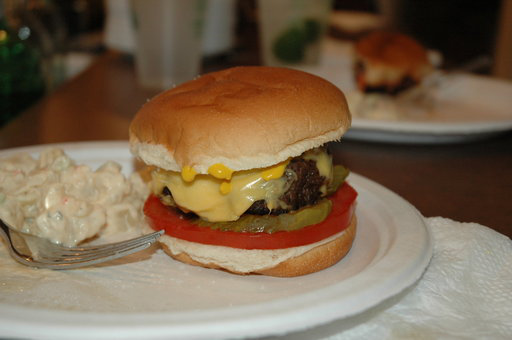

In [10]:
import random
from PIL import Image

# random.seed(42) # устанавливаем псевдослучайное число, будет выодится всегда одно и тоже изображние
random.seed() # будет отображаться случайное изображение

# Получаем все пути к рандомным изображениям
image_path_list = list(image_path.glob("*/*/*.jpg"))

# Возьмем рандомный путь, внимательно, если у random.seed(42) будет параметр, как тут равный 42, пусть всегда будет браться к этому 42 изображению
random_image_path = random.choice(image_path_list)

# Получаем класс изображения из пути, (класс изображения - это имя каталога, в котором хранится изображение)
image_class = random_image_path.parent.stem

# Открываем изображение
img = Image.open(random_image_path)

# Печатаем данные изображения
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}") 
print(f"Image width: {img.width}")
img

Отобразить изображение можно с помощью matplotlib.pyplot.imshow(), за исключением того, что сначала нам нужно преобразовать изображение в массив NumPy.

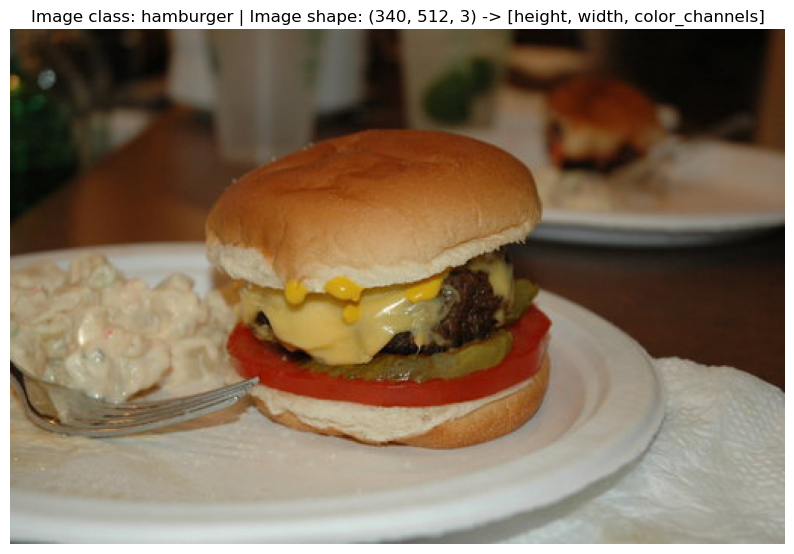

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Turn the image into an array
img_as_array = np.asarray(img)

# Plot the image with matplotlib
plt.figure(figsize=(10, 7))
plt.imshow(img_as_array)
plt.title(f"Image class: {image_class} | Image shape: {img_as_array.shape} -> [height, width, color_channels]")
plt.axis(False);

<p>3. Преобразование данных

Прежде чем использовать изображения в PyTorch, необходимо сделать следующее:
- Перевести изображение в тензоры (числовые представления изображений).
- Записать тензорный набор данных в torch.utils.data.Dataset, затем в torch.utils.data.DataLoader.

Ипортнем библиотечки. Так как мы работаем с изображениями, то будем использовать [torchvision.datasets](https://pytorch.org/vision/stable/datasets.html):

In [13]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

<p>3.1.Преобразование данных с помощьюtorchvision.transforms

In [14]:
data_transform = transforms.Compose([
    # Меняем размер изображения на 64x64, можете поменять и посмотреть
    transforms.Resize(size=(64, 64)),
    # Можно повернуть изображение по горизонтали
    transforms.RandomHorizontalFlip(p=0.5), # p = вероятность переворота, 0.5 = 50% шанс, можете поэксперементировать
    # Преобразуем изображения в torch.Tensor
    transforms.ToTensor() # эта строчка преобразует все значения пикселей от 0 до 255 в значения от 0.0 до 1.0 ])
])

Пример функции для того, чтобы попробовать преобразования на ихображениях:

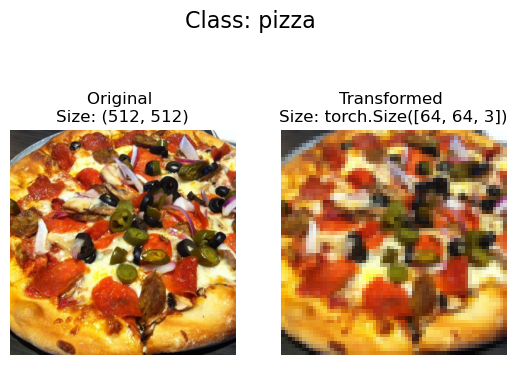

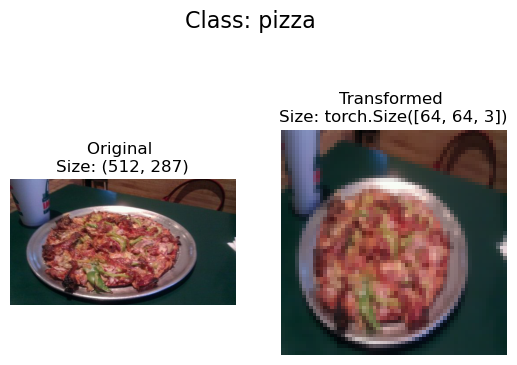

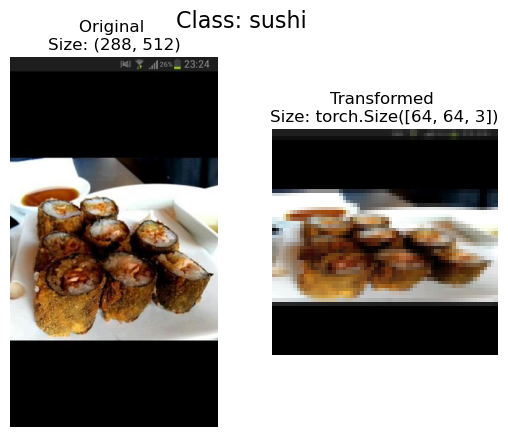

In [15]:
def plot_transformed_images(image_paths, transform, n=3, seed=None): # параметр seed=None означает рандомные изображения, попробуйте seed=42 или любое число
    # n=3 - это три пути к трем изображениям, которые будут отрисованы ниже, поэксперементируйте
    # image_paths (список): список путей к целевым изображениям
    # transform (PyTorch Transforms): преобразует к изображениям
    random.seed(seed)
    random_image_paths = random.sample(image_paths, k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(1, 2)
            ax[0].imshow(f) 
            ax[0].set_title(f"Original \nSize: {f.size}")
            ax[0].axis("off")

            # Преобразования и построение изображений
            # permute() изменит форму изображения в соответствии с matplotlib 
            # PyTorch по умолчанию — [C, H, W], Matplotlib — [H, W, C]
            transformed_image = transform(f).permute(1, 2, 0) 
            ax[1].imshow(transformed_image) 
            ax[1].set_title(f"Transformed \nSize: {transformed_image.shape}")
            ax[1].axis("off")

            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)

plot_transformed_images(image_path_list, 
                        transform=data_transform, 
                        n=3) # не забудем тут тоже поменять n=3 то число, что меняли в начале)))

<p>Вообще, чем больше изображение и качественнее, тем больше информации может быть восстановлено моделью, но это требует и больше вычислительных мощностей.
<p>Например, изображение размера [256, 256, 3] будет иметь в 16 раз больше пикселей, чем изображение размера [64, 64, 3]((256*256*3)/(64*64*3)=16).

<p>4. Вариант 1. Загрузка данных изображения с помощьюImageFolder

Преобразуем данные в форму Dataset, которую будет использовать PyTorch.

После преобразования в тензорный вид, можно использовать стандуртный класс торча [torchvision.datasets.ImageFolder](https://pytorch.org/vision/stable/generated/torchvision.datasets.ImageFolder.html#torchvision.datasets.ImageFolder)

In [16]:
# Воспоьзуемся ImageFolder для создания набора данных
from torchvision import datasets
train_data = datasets.ImageFolder(root=train_dir, # целевая папка изображений
                                  transform=data_transform, # преобразование для работы с данными (изображениями)
                                  target_transform=None)

test_data = datasets.ImageFolder(root=test_dir, 
                                 transform=data_transform)

print(f"Train data:\n{train_data}\nTest data:\n{test_data}")

Train data:
Dataset ImageFolder
    Number of datapoints: 2400
    Root location: data\su_ham_pizz\train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )
Test data:
Dataset ImageFolder
    Number of datapoints: 600
    Root location: data\su_ham_pizz\test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )


Получаем имена классов в виде списка:

In [17]:
# Get class names as a list
class_names = train_data.classes
class_names

['hamburger', 'pizza', 'sushi']

Получаем имена классов в виде словаря:

In [18]:
class_dict = train_data.class_to_idx
class_dict

{'hamburger': 0, 'pizza': 1, 'sushi': 2}

Сколько всего данных:

In [19]:
len(train_data), len(test_data)

(2400, 600)

Можно индексировать train_data и test_data, чтобы найти образцы и их целевые метки:

In [20]:
img, label = train_data[0][0], train_data[0][1]
print(f"Image tensor:\n{img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")

Image tensor:
tensor([[[0.4275, 0.6353, 0.6745,  ..., 0.4627, 0.4902, 0.5020],
         [0.4275, 0.5725, 0.5961,  ..., 0.4196, 0.4824, 0.4745],
         [0.4078, 0.5373, 0.5451,  ..., 0.3804, 0.4235, 0.4549],
         ...,
         [0.5333, 0.5294, 0.4588,  ..., 0.8392, 0.8863, 0.8157],
         [0.5373, 0.5373, 0.4824,  ..., 0.8667, 0.7647, 0.6549],
         [0.5451, 0.5255, 0.4980,  ..., 0.7451, 0.6275, 0.4549]],

        [[0.2471, 0.3765, 0.3922,  ..., 0.6510, 0.6588, 0.6784],
         [0.2235, 0.3176, 0.3176,  ..., 0.6235, 0.6431, 0.6314],
         [0.2196, 0.2902, 0.2824,  ..., 0.5765, 0.6000, 0.5882],
         ...,
         [0.4118, 0.3961, 0.3608,  ..., 0.6353, 0.6941, 0.5765],
         [0.4078, 0.4039, 0.3725,  ..., 0.7255, 0.5569, 0.4275],
         [0.3961, 0.4039, 0.3843,  ..., 0.5412, 0.4196, 0.3255]],

        [[0.0745, 0.0510, 0.0471,  ..., 0.9412, 0.9451, 0.9529],
         [0.0745, 0.0510, 0.0431,  ..., 0.9333, 0.9373, 0.9137],
         [0.0902, 0.0667, 0.0510,  ..., 0.89

Сейчас изображения представлены в виде тензора (с shape [3, 64, 64]), а метки представлены в виде целых чисел, относящихся к определенному классу (на которые ссылается атрибу тclass_to_idx).

Построим тензор с помощью matplotlib. Сначала изменяем порядок представления, чтобы была совместимость. Размеры изображения указаны в формате CHW (цветовые каналы, высота, ширина), но в matplotlib предпочтительны HWC (высота, ширина, цветовые каналы).

Original shape: torch.Size([3, 64, 64]) -> [color_channels, height, width]
Image permute shape: torch.Size([64, 64, 3]) -> [height, width, color_channels]


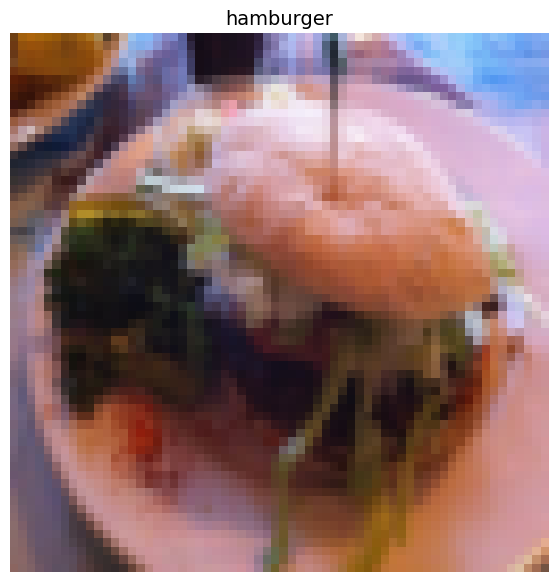

In [21]:
# Меняем порядок
img_permute = img.permute(1, 2, 0)

# Отображаем параметры изначальные и измененные
print(f"Original shape: {img.shape} -> [color_channels, height, width]")
print(f"Image permute shape: {img_permute.shape} -> [height, width, color_channels]")

# Отображаем изображение
plt.figure(figsize=(10, 7))
plt.imshow(img.permute(1, 2, 0))
plt.axis("off")
plt.title(class_names[label], fontsize=14);

Изображение стало более пиксельным, т.е. менее качественным. Это связано с тем, что его размер изменяется на 64x64 пикселя.

<p>4.1 Преобразование загруженных изображений в DataLoader-файлы

Пойдем дальше. Нам нужно загрузить наш преобразованный набор данных в DataLoader. Это можно сделать с помощью [torch.utils.data.DataLoader](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader).

Для чего это делать? Это позволяет преобразовать наш набор данных в интерпертируемых для модели.

In [22]:
# Превращаем обучающие и тестовые наборы данных в DataLoaders
from torch.utils.data import DataLoader
train_dataloader = DataLoader(dataset=train_data, 
                              batch_size=1, # сколько изображений будет в баче
                              num_workers=1, # сколько подпроцессов будет создано для загрузки данных, помним, чем выше число, тем больше кушаем ресурсов
                              shuffle=True) # если хотим перемешать данные, ставим True

test_dataloader = DataLoader(dataset=test_data, 
                             batch_size=1, 
                             num_workers=1, 
                             shuffle=False) # тестовые данные обычно не нужно перемешивать  

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x246de417d50>,
 <torch.utils.data.dataloader.DataLoader at 0x246de4c2150>)

Проверим формы:

In [23]:
img, label = next(iter(train_dataloader))

# Размер бача теперь будет равен 1. Попробуйте изменить параметр batch_size выше и посмотрите, что произойдет.
print(f"Image shape: {img.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label.shape}")

Image shape: torch.Size([1, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([1])


<p>5. Вариант 2. Загрузка данных изображения с помощью пользовательского Dataset

Можно написать свой собственный способ загрузки наборов данных. Сложно, но можно. Плюсы и минусы:
- Можно создавать наборы данных из чего угодно, однако может не сработать).
- Не ограничиваемся предварительно созданными Datasetфункциями PyTorch. Однако, можно накосячить с ошибками и производитеьностью.

Возьмем:
- torchvision.datasets.ImageFolder() - создает подклассы
- torch.utils.data.Dataset - базовый класс для всех наборов данных в PyTorch

Библиотечки:

In [24]:
import os # работа с каталогами
import pathlib # работа с путями
import torch

from PIL import Image # для загурзки изображений
from torch.utils.data import Dataset # для создания своего набора данных
from torchvision import transforms # преобразование в тензоры
from typing import Tuple, Dict, List # добавление подсказок типов

Использование атрибутов train_data.classes и train_data.class_to_idx через torchvision.datasets.ImageFolder()

In [25]:
train_data.classes, train_data.class_to_idx

(['hamburger', 'pizza', 'sushi'], {'hamburger': 0, 'pizza': 1, 'sushi': 2})

Создадим функцию для получения имен файлов

In [26]:
# Устанавливаем путь для целевого каталога 
target_directory = train_dir
print(f"Target directory: {target_directory}")

# Получаем имена классов из целевого каталога 
class_names_found = sorted([entry.name for entry in list(os.scandir(image_path / "train"))])
# os.scandir() - помогает получить имена классов
print(f"Class names found: {class_names_found}")

Target directory: data\su_ham_pizz\train
Class names found: ['hamburger', 'pizza', 'sushi']


<p>5.1.Создание вспомогательной функции для получения имен классов

Напишем функцию для поиска классво в каталоге:

In [27]:
def find_classes(directory: str) -> Tuple[List[str], Dict[str, int]]:
    """Finds the class folder names in a target directory.
    
    Assumes target directory is in standard image classification format.

    Args:
        directory (str): target directory to load classnames from.

    Returns:
        Tuple[List[str], Dict[str, int]]: (list_of_class_names, dict(class_name: idx...))
    
    Example:
        find_classes("food_images/train")
        >>> (["class_1", "class_2"], {"class_1": 0, ...})
    """
    # Получаем имена классов
    classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())
    
    # Выдаем ошибку, если имена классов не найдены
    if not classes:
        raise FileNotFoundError(f"Couldn't find any classes in {directory}.")
        
    # Создаем словарь индексных меток
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
    return classes, class_to_idx

Проверим функцию:

In [28]:
find_classes(train_dir)

(['hamburger', 'pizza', 'sushi'], {'hamburger': 0, 'pizza': 1, 'sushi': 2})

<p>5.2 Создаем Dataset для репликации ImageFolder

Теперь создаем Dataset, с помощью torchvision.datasets.ImageFolder().

In [29]:
# Наследуется от torch.utils.data.Dataset
from torch.utils.data import Dataset

# Создаем подкласс torch.utils.data.Dataset
class ImageFolderCustom(Dataset):
    
    # Инициализируем подкласс с параметром targ_dir и transform
    def __init__(self, targ_dir: str, transform=None) -> None:
        
        # Создаем несколько атрибутов
        # Получаем все пути к изображениям
        self.paths = list(pathlib.Path(targ_dir).glob("*/*.jpg"))
        # Преобразуем параметры
        self.transform = transform
        # Создаем классы и атрибут class_to_idx
        self.classes, self.class_to_idx = find_classes(targ_dir)

    # Создаем функцию для загрузки изображений
    def load_image(self, index: int) -> Image.Image:
        "Opens an image via a path and returns it."
        image_path = self.paths[index]
        return Image.open(image_path) 
    
    # Перезапишем метод __len__() (необязательно, но рекомендуется для подклассов torch.utils.data.Dataset)
    def __len__(self) -> int:
        "Returns the total number of samples."
        return len(self.paths)
    
    # Перезапишем метод __getitem__() (требуется для подклассов torch.utils.data.Dataset)
    def __getitem__(self, index: int) -> Tuple[torch.Tensor, int]:
        "Returns one sample of data, data and label (X, y)."
        img = self.load_image(index)
        class_name  = self.paths[index].parent.name # ожидает путь в data_folder/class_name/image.jpeg
        class_idx = self.class_to_idx[class_name]

        # Трансформируем при необходимости
        if self.transform:
            return self.transform(img), class_idx # возвращаемые данные, метка (X, y)
        else:
            return img, class_idx # возвращаемые данные, метка (X, y)

Можно перенести этот код в файл data_loader.py и использовать когда вам нужно.

Можно преобразовать данные:

In [30]:
# Аугментация тренировочного набора
train_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

# Don't augment test data, only reshape
test_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

Преобразование в Dataset через использование нашего собственного ImageFolderCustom класса.

In [31]:
train_data_custom = ImageFolderCustom(targ_dir=train_dir, 
                                      transform=train_transforms)
test_data_custom = ImageFolderCustom(targ_dir=test_dir, 
                                     transform=test_transforms)
train_data_custom, test_data_custom

(<__main__.ImageFolderCustom at 0x246dd093e10>,
 <__main__.ImageFolderCustom at 0x246de4ca510>)

In [32]:
len(train_data_custom), len(test_data_custom)

(2400, 600)

In [33]:
train_data_custom.classes

['hamburger', 'pizza', 'sushi']

In [34]:
train_data_custom.class_to_idx

{'hamburger': 0, 'pizza': 1, 'sushi': 2}

Проверяем равенство между нашим пользовательским набором данных и набором данных ImageFolder.

In [35]:
print((len(train_data_custom) == len(train_data)) & (len(test_data_custom) == len(test_data)))
print(train_data_custom.classes == train_data.classes)
print(train_data_custom.class_to_idx == train_data.class_to_idx)

True
True
True


<p>5.3.Создаем функцию для отображения случайных изображений

Создадим функцию для отображения случайных изображений:

In [36]:
# Возьмем набор данных и список имен классов
def display_random_images(dataset: torch.utils.data.dataset.Dataset,
                          classes: List[str] = None,
                          n: int = 10,
                          display_shape: bool = True,
                          seed: int = None):
    
    # Отрегулируем отображение, если n слишком велико
    if n > 10:
        n = 10
        display_shape = False
        print(f"For display purposes, n shouldn't be larger than 10, setting to 10 and removing shape display.")
    
    # Установим случайное начальное число
    if seed:
        random.seed(seed)

    # Получаем индексы случайной выборки
    random_samples_idx = random.sample(range(len(dataset)), k=n)

    # Натсройка размеров изображения
    plt.figure(figsize=(16, 8))

    # Перебираем сэмплы и отображаем случайные сэмплы 
    for i, targ_sample in enumerate(random_samples_idx):
        targ_image, targ_label = dataset[targ_sample][0], dataset[targ_sample][1]

        # Настраиваем форму тензора изображения для построения графика: [color_channels, height, width] -> [color_channels, height, width]
        targ_image_adjust = targ_image.permute(1, 2, 0)

        # Скорректированные изображения
        plt.subplot(1, n, i+1)
        plt.imshow(targ_image_adjust)
        plt.axis("off")
        if classes:
            title = f"class: {classes[targ_label]}"
            if display_shape:
                title = title + f"\nshape: {targ_image_adjust.shape}"
        plt.title(title)

Проверяем функцию отображения случайных изображений из созданного ImageFolder набора данных:

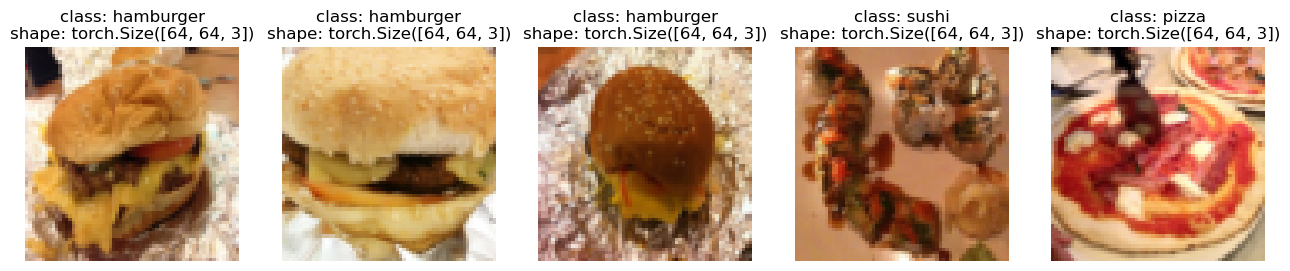

In [37]:
display_random_images(train_data, 
                      n=5, 
                      classes=class_names,
                      seed=None)

Посмотрим случайные изображения из набора данных ImageFolderCustom:

For display purposes, n shouldn't be larger than 10, setting to 10 and removing shape display.


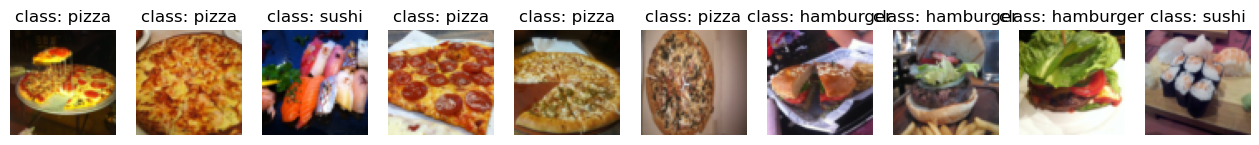

In [38]:
display_random_images(train_data_custom, 
                      n=12, 
                      classes=class_names,
                      seed=None) # Попробуйте установить начальное значение для воспроизводимых изображений

<p>5.4. Превращаем пользовательские загруженные изображения в DataLoader-файлы

Преобразуем загруженные изображения в DataLoader файлы.

In [39]:
# Протестируем пользовательский набор данных и загрузчик данных
from torch.utils.data import DataLoader
train_dataloader_custom = DataLoader(dataset=train_data_custom, # используем обучающий набор данных
                                     batch_size=1, # размер бача
                                     num_workers=0, # подпроцессы
                                     shuffle=True) # перемешивание

test_dataloader_custom = DataLoader(dataset=test_data_custom, # используем тестовый набор данных
                                    batch_size=1, 
                                    num_workers=0, 
                                    shuffle=False) # обычно не нужно для тестовых

train_dataloader_custom, test_dataloader_custom

(<torch.utils.data.dataloader.DataLoader at 0x246de691e10>,
 <torch.utils.data.dataloader.DataLoader at 0x246de302b90>)

In [40]:
# Получить изображение и метку из пользовательского DataLoader
img_custom, label_custom = next(iter(train_dataloader_custom))

# Размер бача равен 1. Попробуйте изменить параметр batch_size выше и посмотрите, что произойдет.
print(f"Image shape: {img_custom.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label_custom.shape}")

Image shape: torch.Size([1, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([1])


<p>6. Другие формы преобразований (увеличение данных) (у меня не работает, т.к. низкая версия торча, накатывать все с нуля лень, у вас при новой версии в колабе работать будет)

Увеличение данных

In [41]:
from torchvision import transforms

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    # следующая строка в коменте, потому что на моей версии она не работает, у вас должна
    #transforms.TrivialAugmentWide(num_magnitude_bins=31), # интенсивность 
    transforms.ToTensor() # используем ToTensor(), чтобы получить все между 0 и 1
])

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)), 
    transforms.ToTensor()
])

Тестирование аугментации:

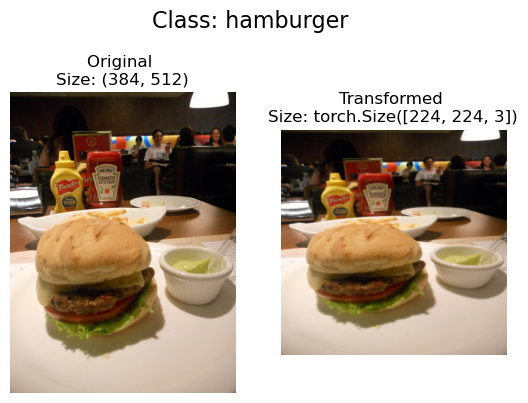

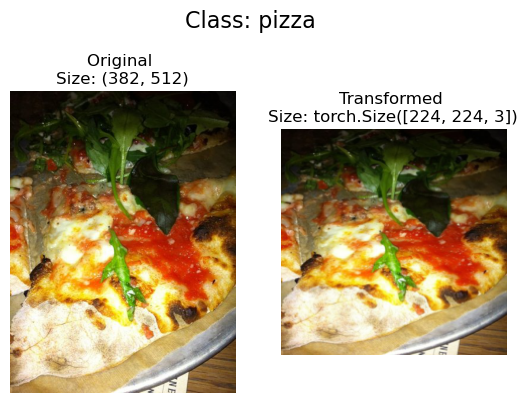

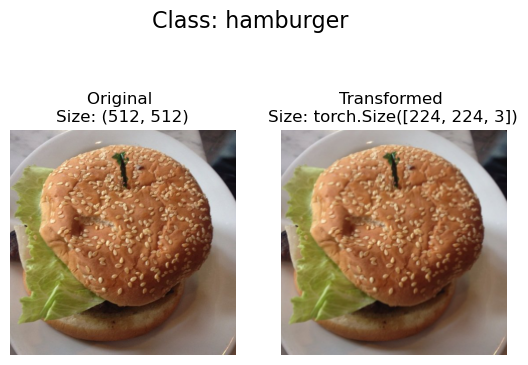

In [42]:
# Получить все пути к изображениям
image_path_list = list(image_path.glob("*/*/*.jpg"))

# Отобразим случайные изображения
plot_transformed_images(
    image_paths=image_path_list,
    transform=train_transforms,
    n=3,
    seed=None
)

<p>7. Модель без увеличения данных

7.1 Создание преобразований и загрузка данных для модели

In [43]:
# Создаем простое преобразование
simple_transform = transforms.Compose([ 
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

In [44]:
# Загрузка и преобразование данных
from torchvision import datasets
train_data_simple = datasets.ImageFolder(root=train_dir, transform=simple_transform)
test_data_simple = datasets.ImageFolder(root=test_dir, transform=simple_transform)

# Превращаем данные в DataLoaders
import os
from torch.utils.data import DataLoader

# Настройка batch size и number of workers 
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()
print(f"Creating DataLoader's with batch size {BATCH_SIZE} and {NUM_WORKERS} workers.")

# Создаем DataLoader
train_dataloader_simple = DataLoader(train_data_simple, 
                                     batch_size=BATCH_SIZE, 
                                     shuffle=True, 
                                     num_workers=NUM_WORKERS)

test_dataloader_simple = DataLoader(test_data_simple, 
                                    batch_size=BATCH_SIZE, 
                                    shuffle=False, 
                                    num_workers=NUM_WORKERS)

train_dataloader_simple, test_dataloader_simple

Creating DataLoader's with batch size 32 and 12 workers.


(<torch.utils.data.dataloader.DataLoader at 0x246d8aebcd0>,
 <torch.utils.data.dataloader.DataLoader at 0x246de876a50>)

7.2. Создание класса модели

In [45]:
class TinyVGG(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int) -> None:
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape, 
                      out_channels=hidden_units, 
                      kernel_size=3, 
                      stride=1, 
                      padding=1), # "valid" (без заполнения) или "same" (вывод имеет ту же форму, что и ввод) или int для определенного числа
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, 
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2) # значение шага по умолчанию совпадает с kernel_size
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            # Каждый слой сети сжимает и изменяет форму входных данных
            nn.Linear(in_features=hidden_units*16*16,
                      out_features=output_shape)
        )
    
    def forward(self, x: torch.Tensor):
        x = self.conv_block_1(x)
        # print(x.shape)
        x = self.conv_block_2(x)
        # print(x.shape)
        x = self.classifier(x)
        # print(x.shape)
        return x
        # возвращает self.classifier(self.conv_block_2(self.conv_block_1(x))) # <- использование преимущества слияния операторов

torch.manual_seed(42)
model_0 = TinyVGG(input_shape=3, # количество цветовых каналов (3 для RGB)
                  hidden_units=10, 
                  output_shape=len(train_data.classes)).to(device)
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

7.3 Попробуем прямой проход на одном изображении (для проверки модели)

In [46]:
# Получем бач изображений и меток из DataLoader
img_batch, label_batch = next(iter(train_dataloader_simple))

# Получаем одно изображение из пакета и растягиваем изображение, чтобы его форма соответствовала модели
img_single, label_single = img_batch[0].unsqueeze(dim=0), label_batch[0]
print(f"Single image shape: {img_single.shape}\n")

# Выполнение прямого прохода на одном изображении
model_0.eval()
with torch.inference_mode():
    pred = model_0(img_single.to(device))
    
print(f"Output logits:\n{pred}\n")
print(f"Output prediction probabilities:\n{torch.softmax(pred, dim=1)}\n")
print(f"Output prediction label:\n{torch.argmax(torch.softmax(pred, dim=1), dim=1)}\n")
print(f"Actual label:\n{label_single}")

Single image shape: torch.Size([1, 3, 64, 64])

Output logits:
tensor([[0.0668, 0.0639, 0.0401]])

Output prediction probabilities:
tensor([[0.3366, 0.3356, 0.3277]])

Output prediction label:
tensor([0])

Actual label:
0


7.4 Использунм torchinfo, чтобы получить представление о формах, проходящих через модель

Самый просто способ посмотреть модель:

In [47]:
print(model_0)

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)


Еще один способ получения информации из модели является использование torchinfo.

torchinfo поставляется с методомs ummary(), который принимает модель PyTorch, а также input_shapeи возвращает то, что происходит, когда тензор перемещается по модели.

torchinfo.summary() дает информацию о модели.

Total params - общее количество параметров в нашей модели.

Estimated Total Size (MB) - размер модели.

input_size - изменение форм ввода и вывода в виде данных об определенных  перемещениях по нашей модели.

In [48]:
try: 
    import torchinfo
except:
    !pip install torchinfo
    import torchinfo
    
from torchinfo import summary
summary(model_0, input_size=[1, 3, 64, 64]) # делаем тестовый проход через пример размера ввода

  Obtaining dependency information for torchinfo from https://files.pythonhosted.org/packages/72/25/973bd6128381951b23cdcd8a9870c6dcfc5606cb864df8eabd82e529f9c1/torchinfo-1.8.0-py3-none-any.whl.metadata


Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 10, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 10, 64, 64]           280
│    └─ReLU: 2-2                         [1, 10, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 10, 64, 64]           910
│    └─ReLU: 2-4                         [1, 10, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 10, 32, 32]           --
├─Sequential: 1-2                        [1, 10, 16, 16]           --
│    └─Conv2d: 2-6                       [1, 10, 32, 32]           910
│    └─ReLU: 2-7                         [1, 10, 32, 32]           --
│    └─Conv2d: 2-8                       [1, 10, 32, 32]           910
│    └─ReLU: 2-9                         [1, 10, 32, 32]           --
│    └─MaxPool2d: 2-10                   [1, 10, 16, 16]           --
├─Sequentia

7.5 Создаем функцию для обучения и тестирования

Так как мы работаем с бачами в DataLoader, необходимо накапливать значения потерь и точности модели во время обучения (суммируя их для каждой партии), а затем корректировать их в конце, прежде чем возвращать их.

In [49]:
def train_step(model: torch.nn.Module, 
               dataloader: torch.utils.data.DataLoader, 
               loss_fn: torch.nn.Module, 
               optimizer: torch.optim.Optimizer):
    model.train()
    
    # Настройка значения потерь и точности
    train_loss, train_acc = 0, 0
    
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        y_pred = model(X)

        loss = loss_fn(y_pred, y)
        train_loss += loss.item() 

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item()/len(y_pred)

    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc

Тоже самое для тестового

In [51]:
def test_step(model: torch.nn.Module, 
              dataloader: torch.utils.data.DataLoader, 
              loss_fn: torch.nn.Module):
    model.eval() 
    
    test_loss, test_acc = 0, 0
    
    with torch.inference_mode():
         for batch, (X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)
    
            test_pred_logits = model(X)

            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()
            
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((test_pred_labels == y).sum().item()/len(test_pred_labels))
            
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc

7.6 Объеденим train_step()и test_step(). Эта функция будет обучать модель, а также оценивать ее.

In [52]:
from tqdm.auto import tqdm

# Принимаем различные параметры, необходимые для обучения и тестирования.
def train(model: torch.nn.Module, 
          train_dataloader: torch.utils.data.DataLoader, 
          test_dataloader: torch.utils.data.DataLoader, 
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5):
    
    # Создаем пустой словарь результатов
    results = {"train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": []
    }
    
    # Цикл через шаги обучения и тестирования для нескольких эпох
    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                           dataloader=train_dataloader,
                                           loss_fn=loss_fn,
                                           optimizer=optimizer)
        test_loss, test_acc = test_step(model=model,
            dataloader=test_dataloader,
            loss_fn=loss_fn)
        
        # Отобразим процесс
        print(
            f"Epoch: {epoch+1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

        # Обновим словарь результатов
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

    # Вернем заполненные результаты в конце эпох
    return results

7.7 Обучение и оценка модели

Создадаем заново model_0. В данном примере это не обязательно, но сделаем это для полноты картины. Затем вызовем функцию train(), передав необходимые параметры.

Обучим на 5 эпохах, чтобы не умереть)

Оптимизатор - torch.nn.CrossEntropyLoss(), так как классификация на 3 класса.

Функция потерь - torch.optim.Adam(), со скоростью обучения 1e-3.

Чтобы увидеть, сколько времени это займет, импортируем timeit.default_timer()метод Python для расчета времени обучения.

In [53]:
torch.manual_seed(42) 
torch.cuda.manual_seed(42)

NUM_EPOCHS = 5

# Пересоздаем экземпляр модели
model_0 = TinyVGG(input_shape=3,  
                  hidden_units=10, 
                  output_shape=len(train_data.classes)).to(device)

# Настройка функции потерь и оптимизатора
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.001)

# Запускаем таймер
from timeit import default_timer as timer 
start_time = timer()

# Обучение модели 
model_0_results = train(model=model_0, 
                        train_dataloader=train_dataloader_simple,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        loss_fn=loss_fn, 
                        epochs=NUM_EPOCHS)

# Завершение таймера и отображение времени
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0993 | train_acc: 0.3496 | test_loss: 1.1082 | test_acc: 0.3421
Epoch: 2 | train_loss: 1.0545 | train_acc: 0.4500 | test_loss: 1.0074 | test_acc: 0.5247
Epoch: 3 | train_loss: 0.9937 | train_acc: 0.5100 | test_loss: 0.9657 | test_acc: 0.5570
Epoch: 4 | train_loss: 0.9479 | train_acc: 0.5508 | test_loss: 0.9365 | test_acc: 0.5696
Epoch: 5 | train_loss: 0.9103 | train_acc: 0.5858 | test_loss: 0.9240 | test_acc: 0.5510
Total training time: 214.070 seconds


7.8 Графики потери модели

In [54]:
# Проверка ключей модели
model_0_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

Извлекаем каждый ключ

In [55]:
def plot_loss_curves(results: Dict[str, List[float]]):
    
    loss = results['train_loss']
    test_loss = results['test_loss']

    accuracy = results['train_acc']
    test_accuracy = results['test_acc']

    epochs = range(len(results['train_loss']))

    plt.figure(figsize=(15, 7))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='train_accuracy')
    plt.plot(epochs, test_accuracy, label='test_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend();

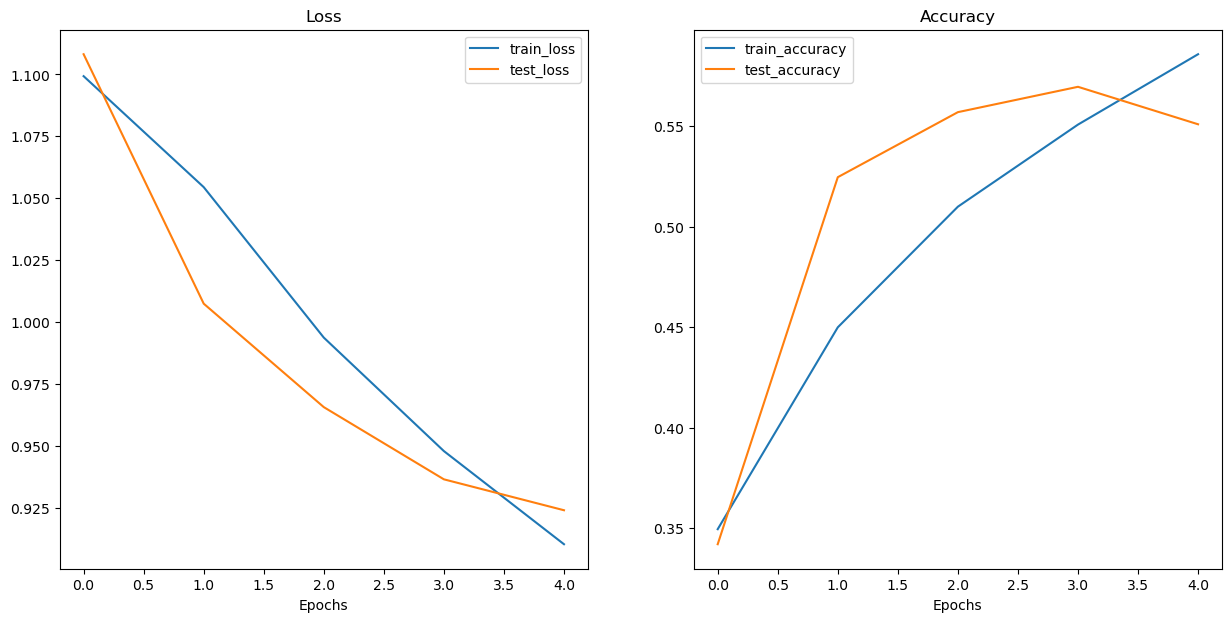

In [56]:
plot_loss_curves(model_0_results)

8. Как должна выглядеть идеальная кривая потерь?

Кратко:
- Если при обучении ниже, чем при тестировании - это overfitting. Это означает, что модель хорошо выучила обучающий набор, но не смогла обощить общие признаки.
- Если потери на тренировочном и тестовом наборы большие, то это можно считать underfitting, т.е. модель недостаточно обучилась.
- Идеальный вариант, если модели близко расположены друг к другу.

[Об интерпритации кривых потерь](https://developers.google.com/machine-learning/testing-debugging/metrics/interpretic)

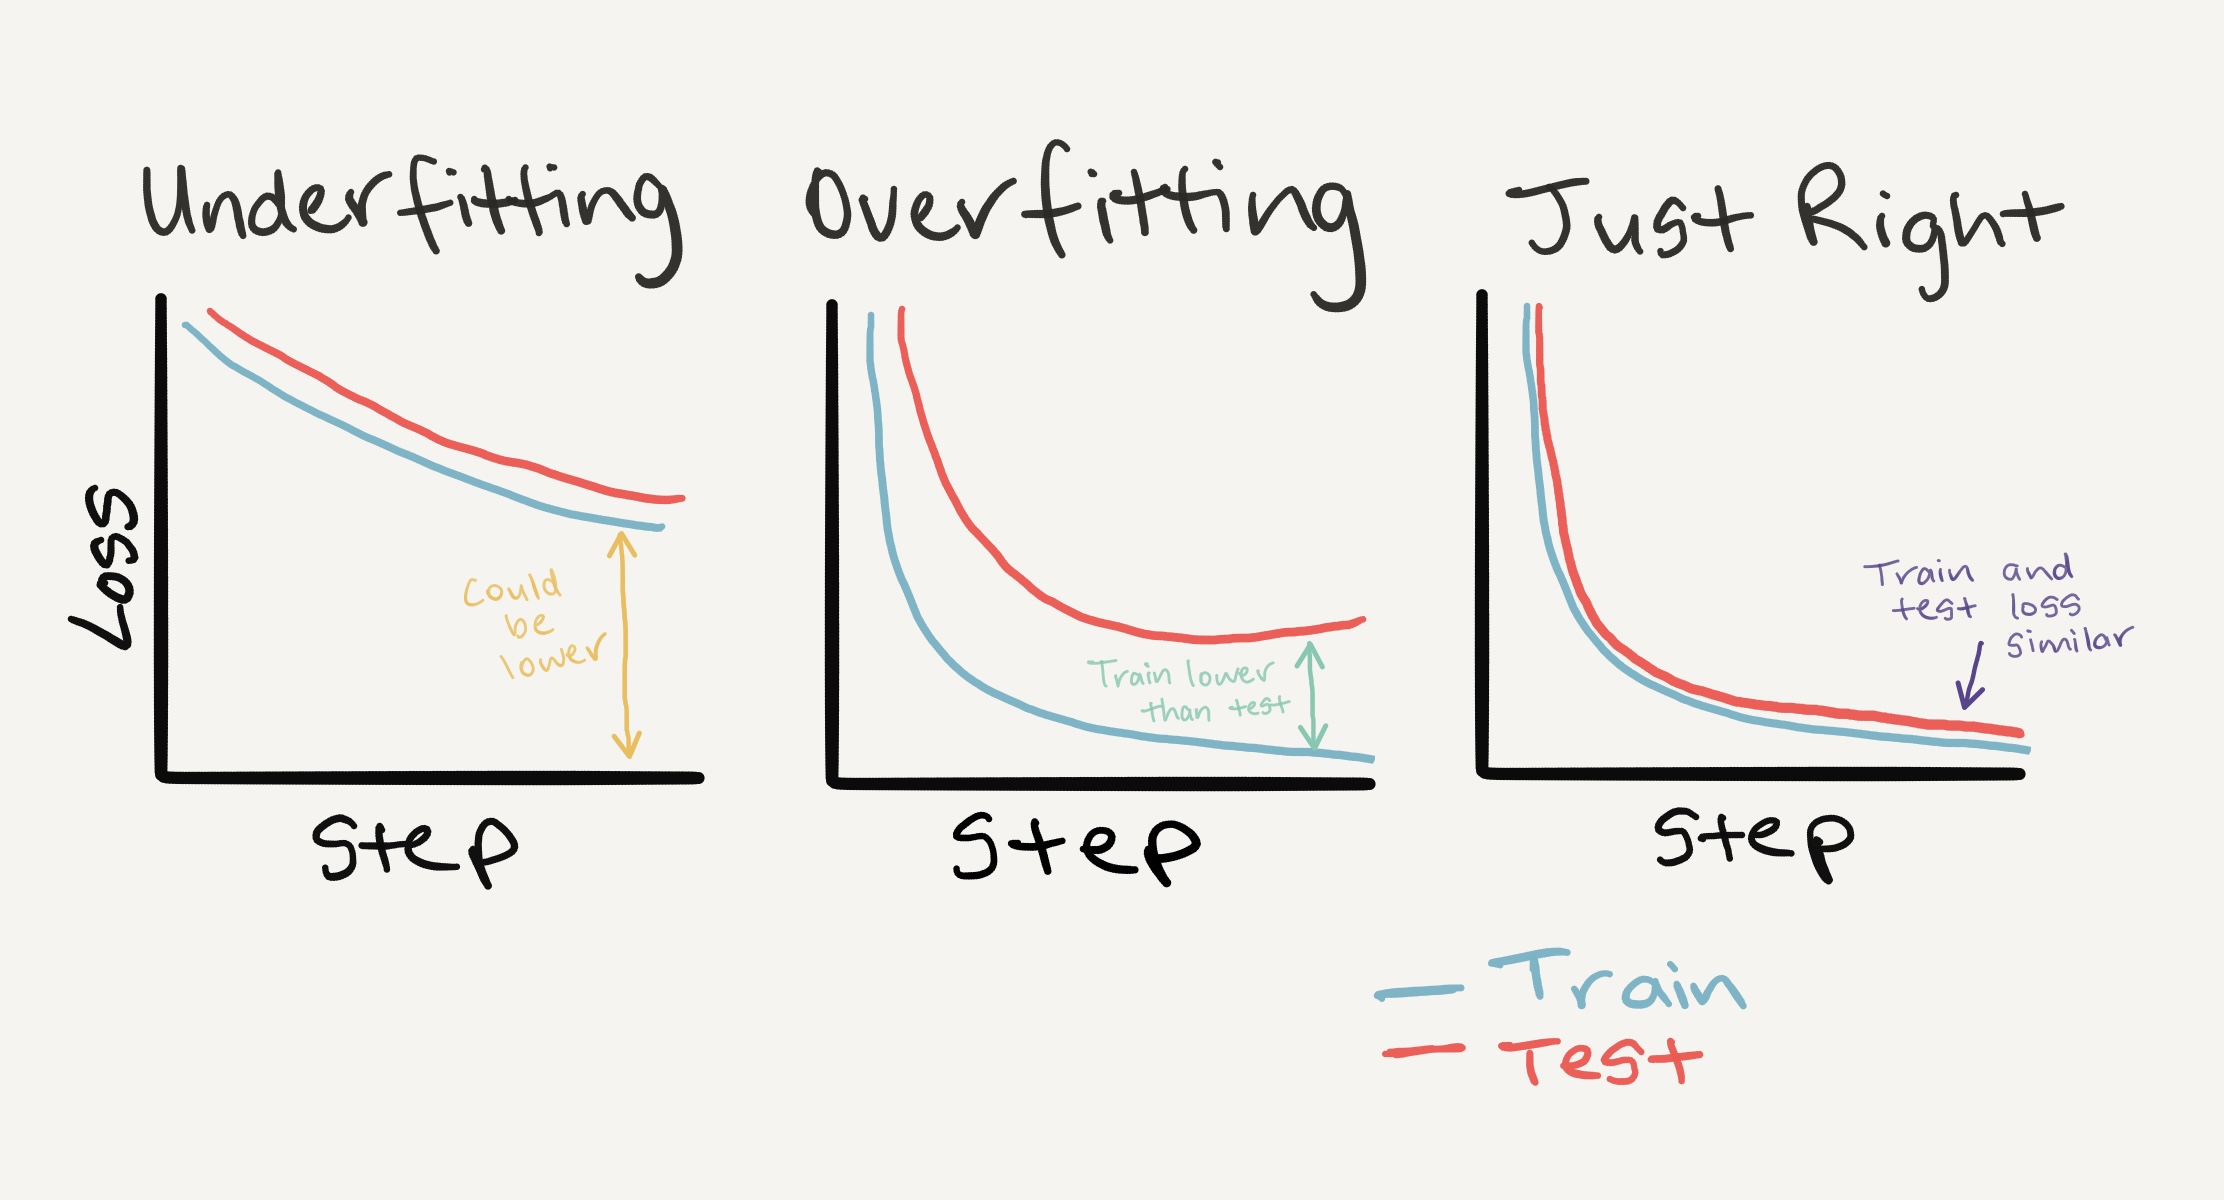

8.1. Как бороться с переобучением

Самый популярный метод - это [регуляризация](https://ml-cheatsheet.readthedocs.io/en/latest/regularization.html):
- получение большего количества данных
- упрощение модели
- расширение данных
- трансферное обучение
- выпадающие слои
- затухание скорости обучения
- ранняя остановка
- и др.

8.2. Как бороться с недообучением

Самые популярные методы:
- повысить количество слоев
- изменить скорость обучения
- трасферное обучение
- увеличить количество эпох
- убрать методы регуляризации

9. Модель с увеличением данных

Опять будем использовать transforms.TrivialAugmentWide. У меня закоменчено, у вас отработать должно.

Создаем модель:

In [57]:
train_transform_trivial_augment = transforms.Compose([
    transforms.Resize((64, 64)),
    #transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor() 
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [58]:
train_data_augmented = datasets.ImageFolder(train_dir, transform=train_transform_trivial_augment)
test_data_simple = datasets.ImageFolder(test_dir, transform=test_transform)

train_data_augmented, test_data_simple

(Dataset ImageFolder
     Number of datapoints: 2400
     Root location: data\su_ham_pizz\train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 600
     Root location: data\su_ham_pizz\test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                ToTensor()
            ))

In [59]:
import os
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

torch.manual_seed(42)
train_dataloader_augmented = DataLoader(train_data_augmented, 
                                        batch_size=BATCH_SIZE, 
                                        shuffle=True,
                                        num_workers=NUM_WORKERS)

test_dataloader_simple = DataLoader(test_data_simple, 
                                    batch_size=BATCH_SIZE, 
                                    shuffle=False, 
                                    num_workers=NUM_WORKERS)

train_dataloader_augmented, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x246de9e8b10>,
 <torch.utils.data.dataloader.DataLoader at 0x246de4c2150>)

9.3. Создание и обучение модели

In [60]:
torch.manual_seed(42)
model_1 = TinyVGG(
    input_shape=3,
    hidden_units=10,
    output_shape=len(train_data_augmented.classes)).to(device)
model_1

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
)

In [61]:
torch.manual_seed(42) 
torch.cuda.manual_seed(42)

NUM_EPOCHS = 5

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_1.parameters(), lr=0.001)

from timeit import default_timer as timer 
start_time = timer()

model_1_results = train(model=model_1, 
                        train_dataloader=train_dataloader_augmented,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        loss_fn=loss_fn, 
                        epochs=NUM_EPOCHS)

end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0954 | train_acc: 0.3592 | test_loss: 1.0692 | test_acc: 0.4841
Epoch: 2 | train_loss: 1.0329 | train_acc: 0.4900 | test_loss: 1.0012 | test_acc: 0.5219
Epoch: 3 | train_loss: 1.0090 | train_acc: 0.5108 | test_loss: 0.9968 | test_acc: 0.5077
Epoch: 4 | train_loss: 0.9861 | train_acc: 0.5221 | test_loss: 0.9954 | test_acc: 0.5049
Epoch: 5 | train_loss: 0.9731 | train_acc: 0.5371 | test_loss: 0.9725 | test_acc: 0.5450
Total training time: 215.946 seconds


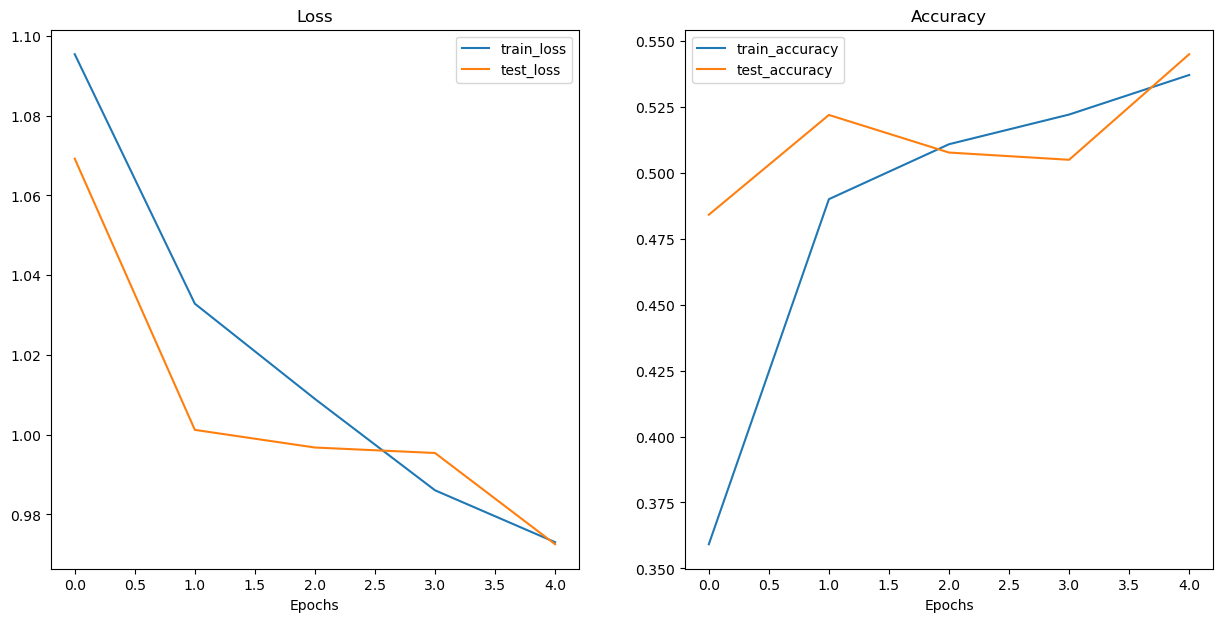

In [62]:
plot_loss_curves ( model_1_results )

10. Сравнение результатов модели:

In [63]:
import pandas as pd
model_0_df = pd.DataFrame(model_0_results)
model_1_df = pd.DataFrame(model_1_results)
model_0_df

,train_loss,train_acc,test_loss,test_acc
0,1.099299,0.349583,1.108162,0.342105
1,1.054496,0.450000,1.007447,0.524671
2,0.993737,0.510000,0.965668,0.557018
3,0.947918,0.550833,0.936516,0.569627
4,0.910314,0.585833,0.924034,0.550987


Используем matplotlib для построения сравнительных графиков

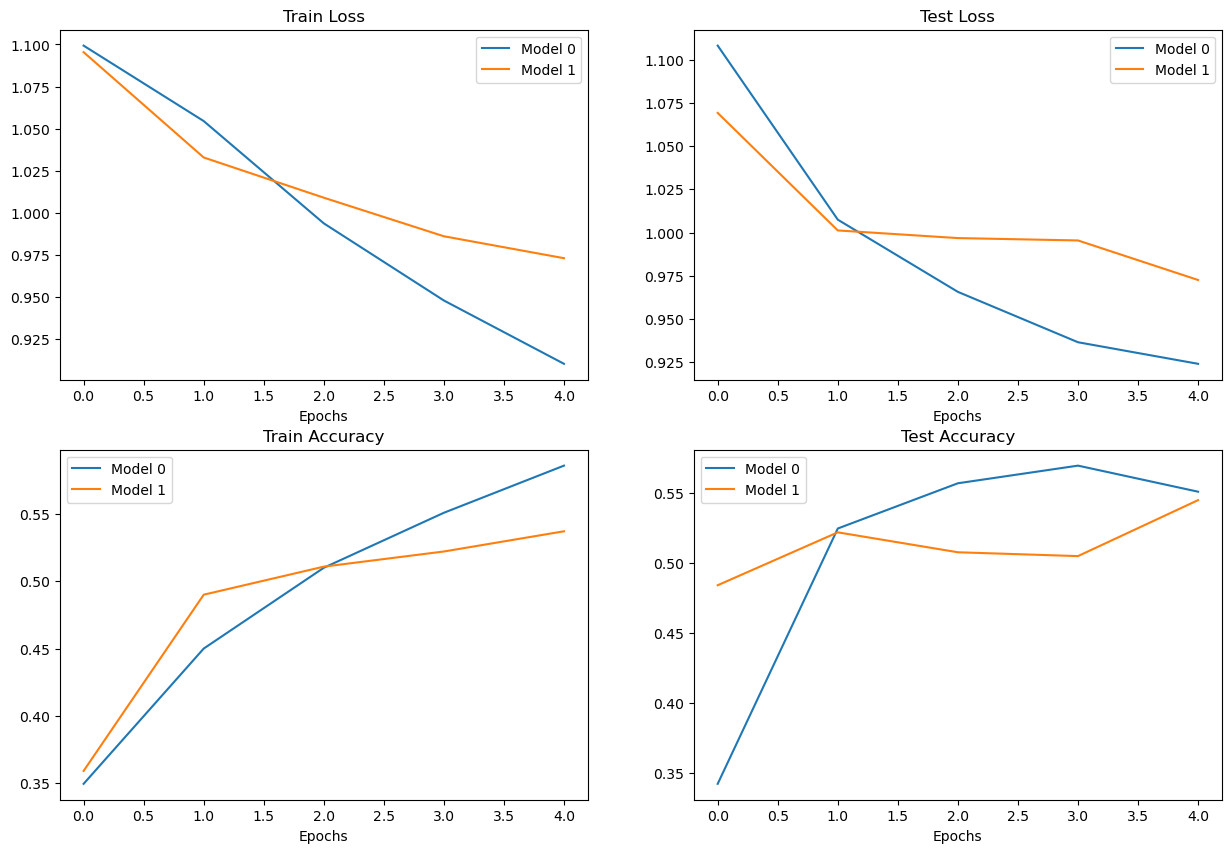

In [64]:
# Нстройка графика
plt.figure(figsize=(15, 10))

# Получаем количесвто эпох
epochs = range(len(model_0_df))

# График потери на обучении
plt.subplot(2, 2, 1)
plt.plot(epochs, model_0_df["train_loss"], label="Model 0")
plt.plot(epochs, model_1_df["train_loss"], label="Model 1")
plt.title("Train Loss")
plt.xlabel("Epochs")
plt.legend()

# График потери на тесте
plt.subplot(2, 2, 2)
plt.plot(epochs, model_0_df["test_loss"], label="Model 0")
plt.plot(epochs, model_1_df["test_loss"], label="Model 1")
plt.title("Test Loss")
plt.xlabel("Epochs")
plt.legend()

# Accuracy на обучении
plt.subplot(2, 2, 3)
plt.plot(epochs, model_0_df["train_acc"], label="Model 0")
plt.plot(epochs, model_1_df["train_acc"], label="Model 1")
plt.title("Train Accuracy")
plt.xlabel("Epochs")
plt.legend()

# Accuracy на тесте
plt.subplot(2, 2, 4)
plt.plot(epochs, model_0_df["test_acc"], label="Model 0")
plt.plot(epochs, model_1_df["test_acc"], label="Model 1")
plt.title("Test Accuracy")
plt.xlabel("Epochs")
plt.legend();

11. Сделаем прогноз на рандомном изображении

In [65]:
# Загружаем изображение
import requests

# Настройка пользовательского пути к изображению
custom_image_path = data_path / "04-pizza-dad.jpg"

# Загрузим изображения, если они не существуют
if not custom_image_path.is_file():
    with open(custom_image_path, "wb") as f:
        request = requests.get("https://static.1000.menu/img/content-v2/08/f3/21103/picca-v-duxovke-s-kolbasoi-i-syrom_1616655833_29_max.jpg")
        print(f"Downloading {custom_image_path}...")
        f.write(request.content)
else:
    print(f"{custom_image_path} already exists, skipping download.")

data\04-pizza-dad.jpg already exists, skipping download.


11.1. Загрузка изображения с помощью PyTorch

Будем использовать torchvision.io.read_image(). Этот метод считывает изображение в формате JPEG или PNG и превращает его в трехмерное изображение RGB или оттенки серого torch.Tensorсо значениями типа данных uint8 в диапазоне [0, 255].

In [66]:
import torchvision

custom_image_uint8 = torchvision.io.read_image(str(custom_image_path))

print(f"Custom image tensor:\n{custom_image_uint8}\n")
print(f"Custom image shape: {custom_image_uint8.shape}\n")
print(f"Custom image dtype: {custom_image_uint8.dtype}")

Custom image tensor:
tensor([[[ 88,  89,  91,  ..., 117, 116, 115],
         [ 88,  90,  91,  ..., 115, 116, 113],
         [ 89,  91,  93,  ..., 114, 113, 111],
         ...,
         [146, 118,  77,  ..., 167, 176, 168],
         [147, 119,  78,  ..., 171, 180, 171],
         [150, 121,  81,  ..., 167, 183, 176]],

        [[100, 101, 103,  ..., 207, 207, 206],
         [100, 102, 103,  ..., 208, 207, 206],
         [101, 103, 105,  ..., 209, 206, 206],
         ...,
         [156, 128,  87,  ..., 195, 199, 189],
         [157, 129,  88,  ..., 200, 205, 193],
         [160, 131,  91,  ..., 196, 208, 198]],

        [[112, 113, 115,  ...,  31,  28,  27],
         [112, 114, 115,  ...,  31,  28,  27],
         [113, 115, 117,  ...,  31,  27,  26],
         ...,
         [166, 138,  97,  ..., 209, 217, 208],
         [167, 139,  98,  ..., 216, 225, 214],
         [170, 141, 101,  ..., 212, 228, 219]]], dtype=torch.uint8)

Custom image shape: torch.Size([3, 960, 1440])

Custom image dtyp

Проверим совместимость изображения с нашей моделью. custom_imageтензор имеет тип данных torch.uint8и его значения находятся между [0, 255]. Но наша модель принимает тензоры изображений типа данных torch.float32 и со значениями между [0, 1]. Поэтому, прежде чем использовать изображение в модельи, нужно преобразовать его в тот же формат, что и данные, на которых обучается модель.

Если это не сделать, то будет ошибка:

In [67]:
model_1.eval()
with torch.inference_mode():
    model_1(custom_image_uint8.to(device))

RuntimeError: Input type (unsigned char) and bias type (float) should be the same

Преобразуем изображение в тот же тип данных, на котором обучалась модель (torch.float32).

In [68]:
# Загружаем пользовательское изображение и преобразуем значения тензора в float32 
custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32)

# Разделим значения пикселей изображения на 255, чтобы получить их между [0, 1]
custom_image = custom_image / 255. 

# Отобразим данные
print(f"Custom image tensor:\n{custom_image}\n")
print(f"Custom image shape: {custom_image.shape}\n")
print(f"Custom image dtype: {custom_image.dtype}")

Custom image tensor:
tensor([[[0.3451, 0.3490, 0.3569,  ..., 0.4588, 0.4549, 0.4510],
         [0.3451, 0.3529, 0.3569,  ..., 0.4510, 0.4549, 0.4431],
         [0.3490, 0.3569, 0.3647,  ..., 0.4471, 0.4431, 0.4353],
         ...,
         [0.5725, 0.4627, 0.3020,  ..., 0.6549, 0.6902, 0.6588],
         [0.5765, 0.4667, 0.3059,  ..., 0.6706, 0.7059, 0.6706],
         [0.5882, 0.4745, 0.3176,  ..., 0.6549, 0.7176, 0.6902]],

        [[0.3922, 0.3961, 0.4039,  ..., 0.8118, 0.8118, 0.8078],
         [0.3922, 0.4000, 0.4039,  ..., 0.8157, 0.8118, 0.8078],
         [0.3961, 0.4039, 0.4118,  ..., 0.8196, 0.8078, 0.8078],
         ...,
         [0.6118, 0.5020, 0.3412,  ..., 0.7647, 0.7804, 0.7412],
         [0.6157, 0.5059, 0.3451,  ..., 0.7843, 0.8039, 0.7569],
         [0.6275, 0.5137, 0.3569,  ..., 0.7686, 0.8157, 0.7765]],

        [[0.4392, 0.4431, 0.4510,  ..., 0.1216, 0.1098, 0.1059],
         [0.4392, 0.4471, 0.4510,  ..., 0.1216, 0.1098, 0.1059],
         [0.4431, 0.4510, 0.4588,  ..

11.2. Прогнозирование

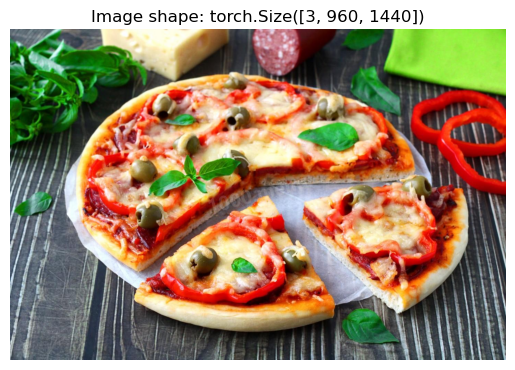

In [69]:
# Отобразим изображение
plt.imshow(custom_image.permute(1, 2, 0)) # необходимо переставить размеры изображения из CHW -> HWC иначе matplotlib выдаст ошибку 
plt.title(f"Image shape: {custom_image.shape}")
plt.axis(False);

Сделаем изображение размером как те, на которых обучалась модель с помощью torchvision.transforms.Resize():

In [70]:
# Изменение размера изображения
custom_image_transform = transforms.Compose([
    transforms.Resize((64, 64)),
])

# Преобразуем целевое значение
custom_image_transformed = custom_image_transform(custom_image)

# Распечатаем исходную форму и новую форму 
print(f"Original shape: {custom_image.shape}")
print(f"New shape: {custom_image_transformed.shape}")

Original shape: torch.Size([3, 960, 1440])
New shape: torch.Size([3, 64, 64])


Попробуем спрогнозировать:

In [71]:
model_1.eval()
with torch.inference_mode():
    custom_image_pred = model_1(custom_image_transformed)

RuntimeError: mat1 and mat2 shapes cannot be multiplied (10x256 and 2560x3)

Забыли про девайс:

In [72]:
model_1.eval()
with torch.inference_mode():
    custom_image_pred = model_1(custom_image_transformed.to(device))

RuntimeError: mat1 and mat2 shapes cannot be multiplied (10x256 and 2560x3)

Ошибка формы.

Модель ожидает тензоры с размером пакета вначале:

In [73]:
model_1.eval()
with torch.inference_mode():
    # Добавляем данные
    custom_image_transformed_with_batch_size = custom_image_transformed.unsqueeze(dim=0)
    
    # Печатаем форму
    print(f"Custom image transformed shape: {custom_image_transformed.shape}")
    print(f"Unsqueezed custom image shape: {custom_image_transformed_with_batch_size.shape}")
    
    # Прогноз
    custom_image_pred = model_1(custom_image_transformed.unsqueeze(dim=0).to(device))

Custom image transformed shape: torch.Size([3, 64, 64])
Unsqueezed custom image shape: torch.Size([1, 3, 64, 64])


Посмотрим предсказание формы:

In [74]:
custom_image_pred

tensor([[-1.0734,  0.5860,  0.1126]])

Получили необработанную форму (logits). Теперь ее надо преобразовать в вероятность и метку прогноза:

In [75]:
# Печать logits прогноза
print(f"Prediction logits: {custom_image_pred}")

# Преобразование logits -> вероятности предсказания (используя torch.softmax() для многоклассовой классификации)
custom_image_pred_probs = torch.softmax(custom_image_pred, dim=1)
print(f"Prediction probabilities: {custom_image_pred_probs}")

# Преобразование вероятностей предсказания -> prediction labels
custom_image_pred_label = torch.argmax(custom_image_pred_probs, dim=1)
print(f"Prediction label: {custom_image_pred_label}")

Prediction logits: tensor([[-1.0734,  0.5860,  0.1126]])
Prediction probabilities: tensor([[0.1049, 0.5515, 0.3435]])
Prediction label: tensor([1])


Метка предсказания все еще находится в форме индекса/тензора. Можно преобразовать его в предсказание имени строкового класса, проиндексировав class_names список.

In [76]:
# Найдем предсказанную метку
custom_image_pred_class = class_names[custom_image_pred_label.cpu()] # put pred label to CPU, otherwise will error
custom_image_pred_class

'pizza'

In [77]:
# Значения вероятностей прогнозов
custom_image_pred_probs

tensor([[0.1049, 0.5515, 0.3435]])

11.3. Создание функции для удобства использования

In [78]:
def pred_and_plot_image(model: torch.nn.Module, 
                        image_path: str, 
                        class_names: List[str] = None, 
                        transform=None,
                        device: torch.device = device):
    """Выполняет прогноз для целевого изображения и строит изображение с его прогнозом"""
    
    # Загружаем изображение и преобразуем значения тензора в float32
    target_image = torchvision.io.read_image(str(image_path)).type(torch.float32)
    
    # Разделяем значения пикселей изображения на 255, чтобы получить их между [0, 1]
    target_image = target_image / 255. 
    
    # Преобразование, если необходимо
    if transform:
        target_image = transform(target_image)
    
    # Убедимся, что модель существует
    model.to(device)
    
    # Включите режим оценки модели и режим вывода 
    model.eval()
    with torch.inference_mode():
        # Добавляем дополнительное измерение к изображению 
        target_image = target_image.unsqueeze(dim=0)
    
        # Делаем прогноз для изображения с дополнительным измерением и отправить его на целевое устройство
        target_image_pred = model(target_image.to(device))
        
    # Преобразуем logits -> вероятности прогноза (используя torch.softmax() для мультиклассовой классификации)
    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

    # Преобразetv вероятностей предсказания -> метки предсказания
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)
    
    # Построtv изображение вместе с прогнозом и вероятностью прогноза 
    plt.imshow(target_image.squeeze().permute(1, 2, 0)) # make sure it's the right size for matplotlib
    if class_names:
        title = f"Pred: {class_names[target_image_pred_label.cpu()]} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    else: 
        title = f"Pred: {target_image_pred_label} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    plt.title(title)
    plt.axis(False);

Проверка функции:

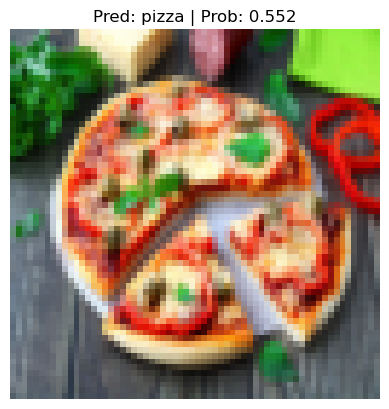

In [79]:
# Предскажем класс
pred_and_plot_image(model=model_1,
                    image_path=custom_image_path,
                    class_names=class_names,
                    transform=custom_image_transform,
                    device=device)
